#Import Libraries

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import tensorflow_datasets as tfds


In [3]:
!pip install -q importlib-resources

#Load Malaria Dataset

In [4]:
(ds_train, ds_val, ds_test), ds_info = tfds.load(
    'malaria',
    split=['train[:80%]', 'train[80%:90%]', 'train[90%:]'],
    shuffle_files=True,
    as_supervised=True,
    with_info=True
)

print("Dataset loaded with separate training, validation, and test splits.")

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/malaria/incomplete.N7FAIR_1.0.0/malaria-train.tfrecord-[0-9][0-9][0-9][0-9…

Dataset malaria downloaded and prepared to /root/tensorflow_datasets/malaria/1.0.0. Subsequent calls will reuse this data.
Dataset loaded with separate training, validation, and test splits.


#Set Hyperparameters

In [5]:
IMG_SIZE = 128
BATCH_SIZE = 32
EPOCHS = 10

class_names = ['Parasitized', 'Uninfected']
num_classes = 2


#Data Preprocessing

In [6]:
def preprocess(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = image / 255.0
    return image, label

In [7]:
train_ds = (
    ds_train.map(preprocess)
    .shuffle(10000, seed=42)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)
val_ds = ds_val.map(preprocess).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = ds_test.map(preprocess).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

#	Data Augmentation

In [8]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

#Build CNN Model

In [9]:
model = models.Sequential([

    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    data_augmentation,

    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(num_classes, activation='softmax')
])

#Compile CNN Model

In [10]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,898 (12.61 MB)

 Trainable params: 3,304,898 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

#	Train CNN Model

In [11]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 37s 35ms/step - accuracy: 0.8827 - loss: 0.2986 - val_accuracy: 0.9365 - val_loss: 0.1901
Epoch 2/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 38s 38ms/step - accuracy: 0.9489 - loss: 0.1666 - val_accuracy: 0.9325 - val_loss: 0.1812
Epoch 3/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 25s 27ms/step - accuracy: 0.9517 - loss: 0.1518 - val_accuracy: 0.9507 - val_loss: 0.1496
Epoch 4/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 37s 45ms/step - accuracy: 0.9524 - loss: 0.1477 - val_accuracy: 0.9539 - val_loss: 0.1633
Epoch 5/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 30s 34ms/step - accuracy: 0.9546 - loss: 0.1412 - val_accuracy: 0.9528 - val_loss: 0.1513
Epoch 6/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 44s 37ms/step - accuracy: 0.9559 - loss: 0.1389 - val_accuracy: 0.9532 - val_loss: 0.1469
Epoch 7/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 29s 33ms/step - accuracy: 0.9566 - loss: 0.1359 - val_accuracy: 0.9561 - val_loss: 0.1329
Epoch 8/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 34s 32ms/step - accuracy: 0.9572 - loss: 0.1330 - 

#	Evaluate CNN on Test Data

In [12]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print("CNN Test Accuracy:", test_accuracy)
print("CNN Test Loss:", test_loss)

87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.9557 - loss: 0.1534
CNN Test Accuracy: 0.9557329416275024
CNN Test Loss: 0.1534223109483719


#CNN Confusion Matrix

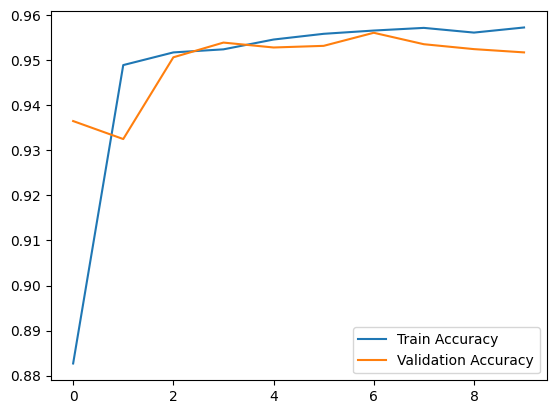

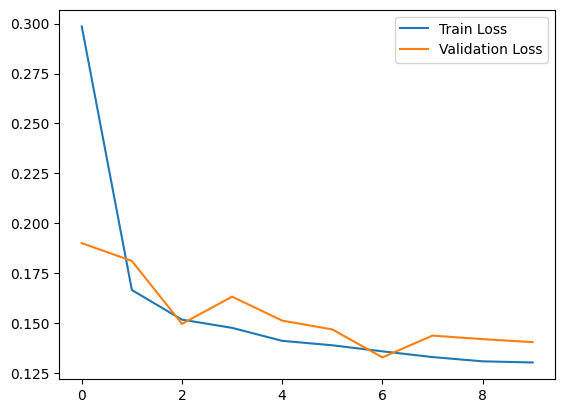

In [13]:
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.show()

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.show()


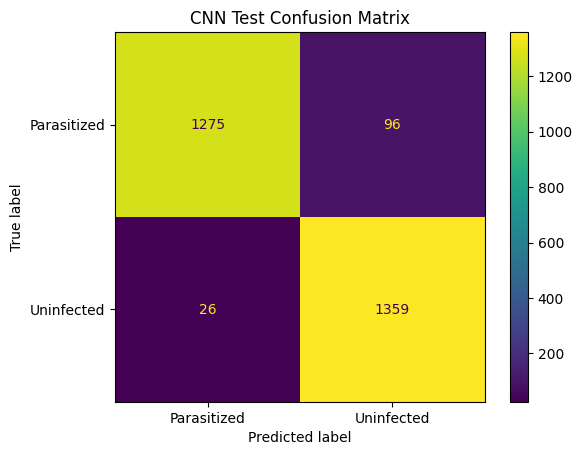

In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np

cnn_y_true = []
cnn_y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)
    cnn_y_true.extend(labels.numpy())
    cnn_y_pred.extend(np.argmax(predictions, axis=1))

cnn_cm = confusion_matrix(cnn_y_true, cnn_y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cnn_cm,
    display_labels=['Parasitized', 'Uninfected']
)
disp.plot()
plt.title("CNN Test Confusion Matrix")
plt.show()

Save CNN Model

In [15]:
model.save("malaria_cnn_model.h5")

#	CNN Sample Predictions

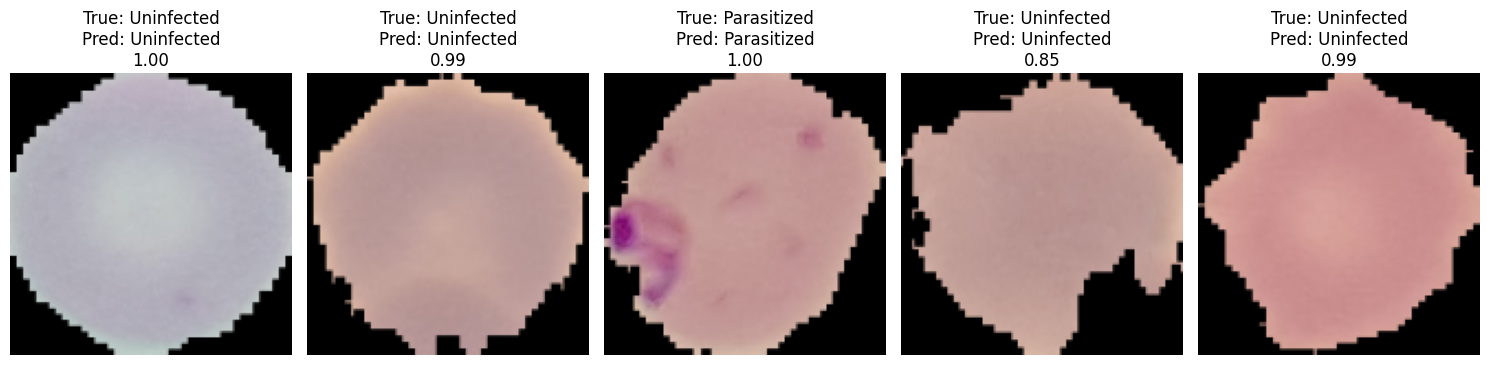

In [16]:
import numpy as np
import matplotlib.pyplot as plt

for images, labels in test_ds.take(1):
    plt.figure(figsize=(15, 10))
    for i in range(min(5, len(images))):
        plt.subplot(1, 5, i + 1)
        plt.imshow(images[i])
        plt.axis("off")
        img_array = np.expand_dims(images[i], axis=0)
        prediction = model.predict(img_array, verbose=0)
        predicted_class = class_names[np.argmax(prediction)]
        true_class = class_names[labels[i].numpy()]
        confidence = np.max(prediction)
        plt.title(f"True: {true_class}\nPred: {predicted_class}\n{confidence:.2f}")
    plt.tight_layout()
    plt.show()

In [17]:
# Install project dependencies before running:
# pip install -r requirements.txt

#Prepare YOLO Dataset

In [18]:
import tensorflow_datasets as tfds
import os
import shutil
import cv2

# Re-create folders so old exported images cannot leak into a new split.
shutil.rmtree("malaria_dataset", ignore_errors=True)

(ds_train_yolo, ds_val_yolo, ds_test_yolo), ds_info_yolo = tfds.load(
    'malaria',
    split=['train[:80%]', 'train[80%:90%]', 'train[90%:]'],
    as_supervised=True,
    with_info=True
)

classes = ['Parasitized', 'Uninfected']
splits = {
    "train": ds_train_yolo,
    "val": ds_val_yolo,
    "test": ds_test_yolo
}

for split_name, dataset in splits.items():
    for class_name in classes:
        os.makedirs(f"malaria_dataset/{split_name}/{class_name}", exist_ok=True)

    for i, (image, label) in enumerate(dataset):
        class_name = classes[int(label.numpy())]
        image_array = image.numpy()
        output_path = f"malaria_dataset/{split_name}/{class_name}/{i}.jpg"
        cv2.imwrite(output_path, cv2.cvtColor(image_array, cv2.COLOR_RGB2BGR))

print("YOLO dataset exported with train, val, and test splits.")

YOLO dataset exported with train, val, and test splits.


#Train YOLO Model

In [20]:
!pip install -q ultralytics

In [21]:
from ultralytics import YOLO

yolo_model = YOLO("yolo11n-cls.pt")

yolo_results = yolo_model.train(
    data="malaria_dataset",
    epochs=10,
    imgsz=128,
    batch=32
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=malaria_dataset, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hs

#Evaluate YOLO on Test Data

In [22]:
# Evaluate only on the held-out test split.
yolo_test_metrics = yolo_model.val(data="malaria_dataset", split="test")
print("YOLO Test Top-1 Accuracy:", yolo_test_metrics.top1)
print("YOLO Test Top-5 Accuracy:", yolo_test_metrics.top5)

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-cls summary (fused): 47 layers, 1,528,586 parameters, 0 gradients, 3.2 GFLOPs
train: /content/malaria_dataset/train... found 22046 images in 2/2 classes ✅ 
val: /content/malaria_dataset/val... found 2756 images in 2/2 classes ✅ 
test: /content/malaria_dataset/test... found 2756 images in 2/2 classes ✅ 
test: Fast image access ✅ (ping: 0.0±0.0 ms, read: 155.5±83.1 MB/s, size: 6.5 KB)
test: Scanning /content/malaria_dataset/test... 2756 images, 0 corrupt: 100% ━━━━━━━━━━━━ 2756/2756 1.6Kit/s 1.7s
test: New cache created: /content/malaria_dataset/test.cache
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 173/173 12.8it/s 13.5s
                   all      0.969          1
Speed: 0.1ms preprocess, 2.8ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /content/runs/classify/val
YOLO Test Top-1 Accuracy: 0.9687953591346741
YOLO Test Top-5 Accuracy: 1.0


In [23]:
cnn_test_loss, cnn_test_accuracy = model.evaluate(test_ds, verbose=1)
print("CNN Test Accuracy:", cnn_test_accuracy)
print("CNN Test Loss:", cnn_test_loss)

87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.9557 - loss: 0.1534
CNN Test Accuracy: 0.9557329416275024
CNN Test Loss: 0.1534223109483719


In [24]:
print("YOLO Test Top-1 Accuracy:", yolo_test_metrics.top1)
print("YOLO Test Top-5 Accuracy:", yolo_test_metrics.top5)

YOLO Test Top-1 Accuracy: 0.9687953591346741
YOLO Test Top-5 Accuracy: 1.0


YOLO Confusion Matrix

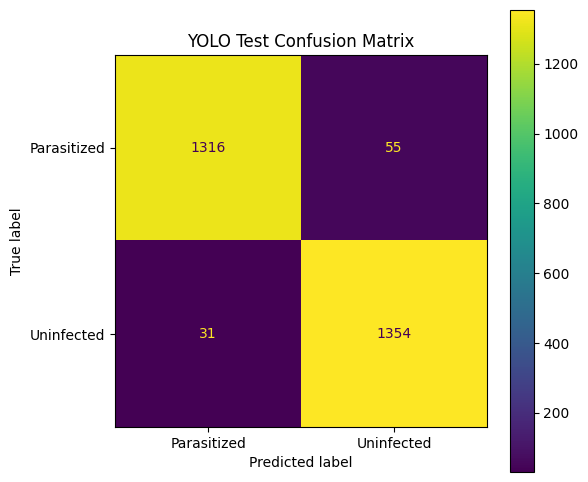

In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import glob
import os

yolo_y_true = []
yolo_y_pred = []
class_names = ['Parasitized', 'Uninfected']
test_image_paths = sorted(glob.glob("malaria_dataset/test/*/*.jpg"))

for img_path in test_image_paths:
    true_class_name = os.path.basename(os.path.dirname(img_path))
    yolo_y_true.append(class_names.index(true_class_name))
    result = yolo_model(img_path, verbose=False)
    yolo_y_pred.append(result[0].probs.top1)

yolo_cm = confusion_matrix(yolo_y_true, yolo_y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=yolo_cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax)
plt.title("YOLO Test Confusion Matrix")
plt.show()

YOLO Sample Predictions

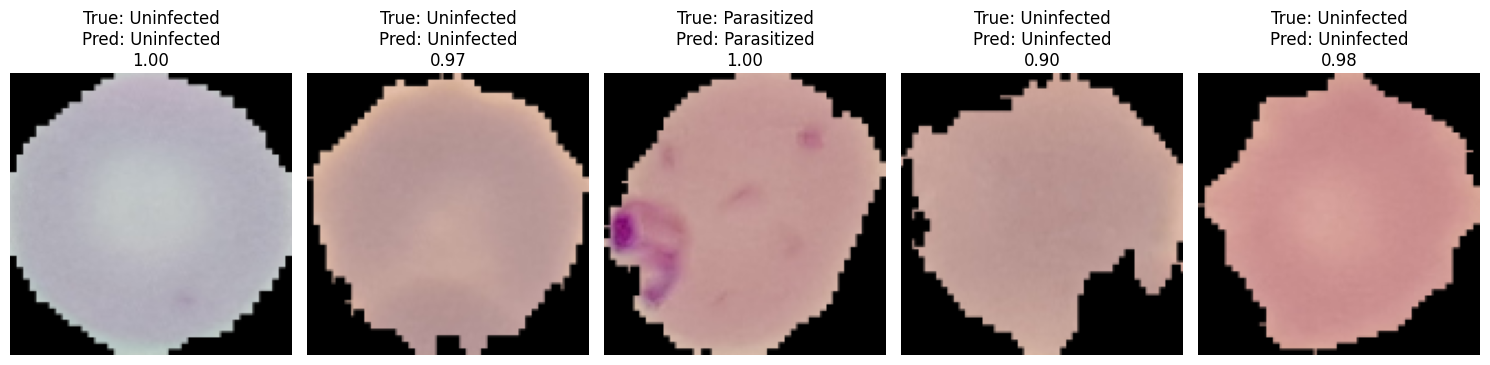

In [26]:
import numpy as np
import matplotlib.pyplot as plt

for images, labels in test_ds.take(1):
    plt.figure(figsize=(15, 10))
    for i in range(min(5, len(images))):
        plt.subplot(1, 5, i + 1)
        plt.imshow(images[i])
        plt.axis("off")
        image_array = (images[i].numpy() * 255).astype("uint8")
        result = yolo_model(image_array, verbose=False)
        predicted_class = class_names[result[0].probs.top1]
        true_class = class_names[labels[i].numpy()]
        confidence = float(result[0].probs.top1conf)
        plt.title(f"True: {true_class}\nPred: {predicted_class}\n{confidence:.2f}")
    plt.tight_layout()
    plt.show()

YOLO Classification Report

In [27]:
from sklearn.metrics import classification_report

print(classification_report(
    yolo_y_true,
    yolo_y_pred,
    target_names=['Parasitized', 'Uninfected']
))

              precision    recall  f1-score   support

 Parasitized       0.98      0.96      0.97      1371
  Uninfected       0.96      0.98      0.97      1385

    accuracy                           0.97      2756
   macro avg       0.97      0.97      0.97      2756
weighted avg       0.97      0.97      0.97      2756



CNN vs YOLO Comparison

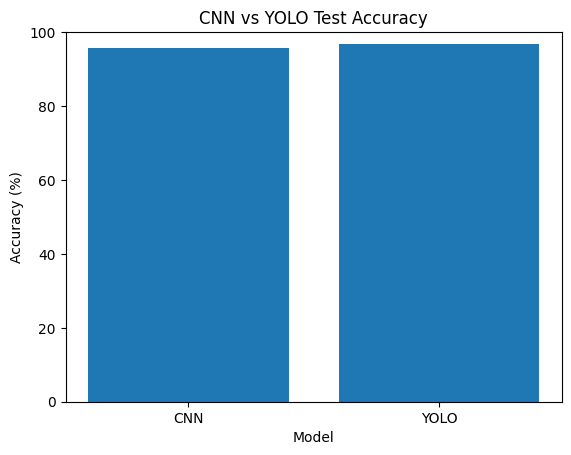

In [28]:
import matplotlib.pyplot as plt

models = ["CNN", "YOLO"]
test_accuracies = [
    cnn_test_accuracy * 100,
    yolo_test_metrics.top1 * 100
]

plt.bar(models, test_accuracies)
plt.title("CNN vs YOLO Test Accuracy")
plt.xlabel("Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.show()

In [29]:
print(f"CNN Test Accuracy: {cnn_test_accuracy * 100:.2f}%")
print(f"YOLO Test Accuracy: {yolo_test_metrics.top1 * 100:.2f}%")

CNN Test Accuracy: 95.57%
YOLO Test Accuracy: 96.88%
